In [28]:
# Data manipulation
import numpy as np
import pandas as pd
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# LinReg Model
from sklearn.linear_model import LinearRegression
# Model Evaluation
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [29]:
df = pd.read_csv('train.csv')

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
# Check the missing values
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Percentage (%)', ascending=False)

In [31]:
missing_summary.round(2)

,Missing Values,Percentage (%)
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


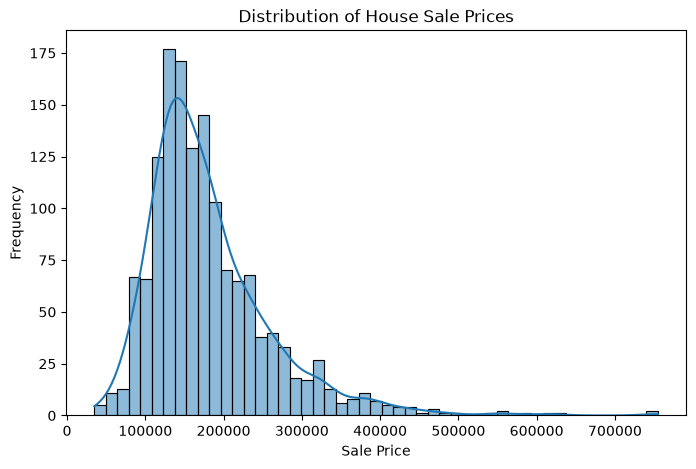

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['SalePrice'], kde=True)

plt.title('Distribution of House Sale Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

In [33]:
# Select numerical columns
numerical_data = df.select_dtypes(include=np.number)
# correlation with Sale Price
correlation = numerical_data.corr()['SalePrice'].sort_values(
    ascending=False
)

In [34]:
correlation 

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

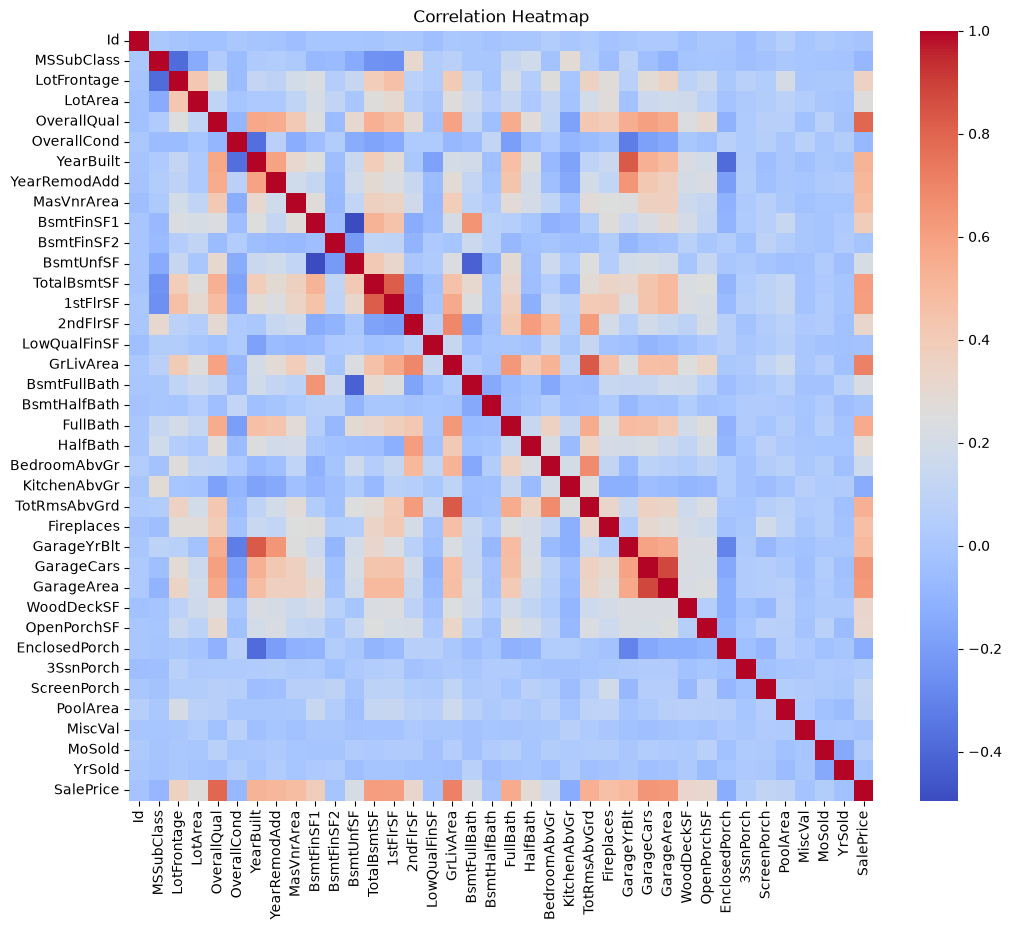

In [35]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    numerical_data.corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Correlation Heatmap')
plt.show()

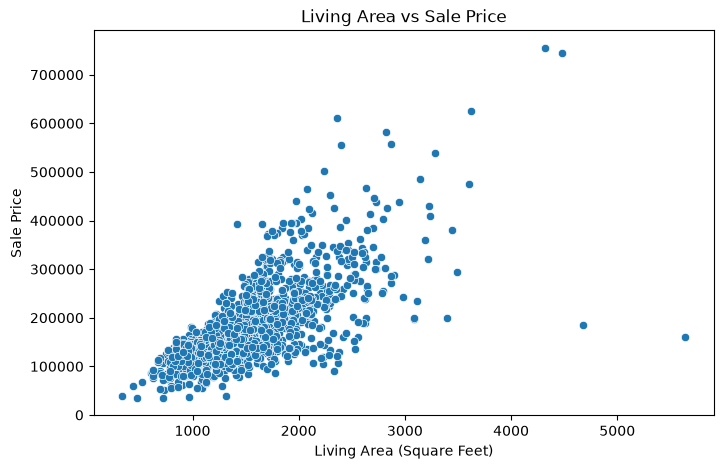

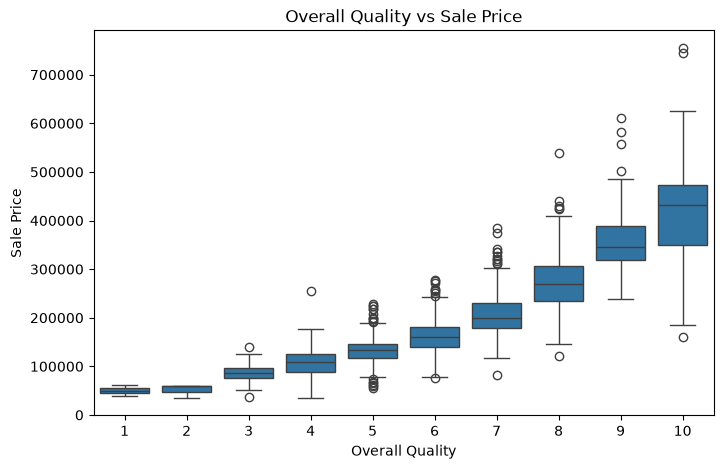

In [36]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice'
)

plt.title('Living Area vs Sale Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('Sale Price')
plt.show()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='OverallQual',
    y='SalePrice'
)

plt.title('Overall Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')
plt.show()

In [37]:
# Drop Column id
df_processed = df.drop(columns=['Id'])

# Separating variable(features and target)
X = df_processed.drop(columns=['SalePrice'])
y = df_processed['SalePrice']

print("Features Shape =", X.shape)
print("Target Shape =", y.shape)

Features Shape = (1460, 79)
Target Shape = (1460,)


In [38]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("X_train Shape = ", X_train.shape)
print("X_test Shape = ", X_test.shape)
print("y_train Shape = ", y_train.shape)
print("y_test Shape = ", y_test.shape)

X_train Shape =  (1022, 79)
X_test Shape =  (438, 79)
y_train Shape =  (1022,)
y_test Shape =  (438,)


In [39]:
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of Numerical Features = ", len(numerical_features))
print("Number of Categorical Features = ", len(categorical_features))

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Apply preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training Data after Preprocessing = ", X_train_processed.shape)
print("Testing Data after Preprocessing = ", X_test_processed.shape)

Number of Numerical Features =  36
Number of Categorical Features =  43
Training Data after Preprocessing =  (1022, 282)
Testing Data after Preprocessing =  (438, 282)


In [40]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train_processed, y_train)

print("Linear Regression model has been trained successfully!")

Linear Regression model has been trained successfully!


In [41]:
# Predict house prices and compare with actual prices 
y_pred = model.predict(X_test_processed)
prediction_result = pd.DataFrame({
    'Actual SalePrice': y_test.values,
    'Predicted SalePrice': y_pred.round(2)
})

In [42]:
prediction_result.head(10)

,Actual SalePrice,Predicted SalePrice
0,154500,157083.46
1,325000,356135.89
2,115000,83756.99
3,159000,178446.75
4,315500,321730.33
5,75500,68773.15
6,311500,236735.41
7,146000,146670.71
8,84500,56822.46
9,135500,154097.44


In [43]:
# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION EVALUATION")
print("--------------------------------")
print(f"Mean Squared Error (MSE) =  {mse:.2f}")
print(f"Root Mean Squared Error (RMSE) = {rmse:.2f}")
print(f"R-squared (R2) = {r2:.4f}")

LINEAR REGRESSION EVALUATION
--------------------------------
Mean Squared Error (MSE) =  780672282.64
Root Mean Squared Error (RMSE) = 27940.51
R-squared (R2) = 0.8881


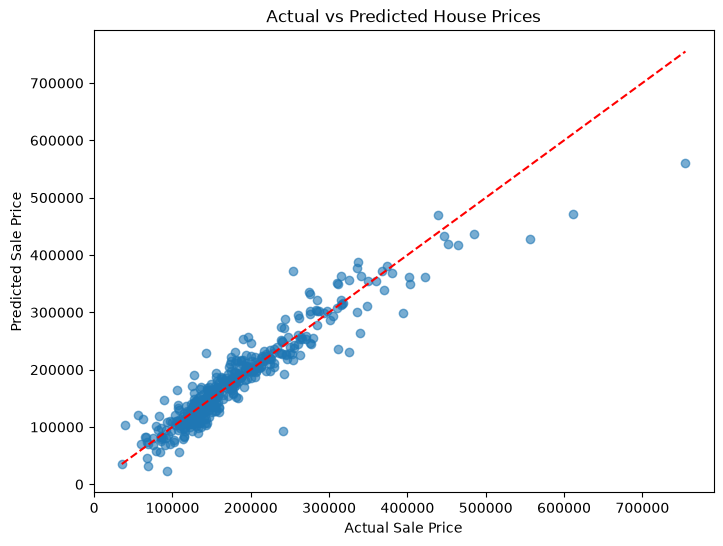

In [44]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price')
plt.title('Actual vs Predicted House Prices')
plt.show()

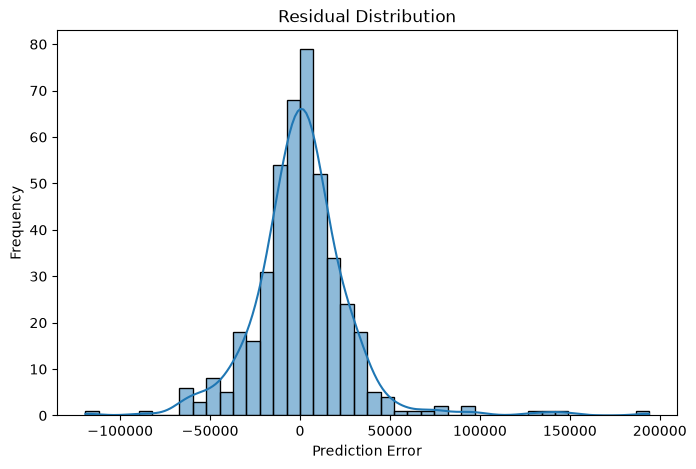

Mean Residual =  1166.6288375903405


In [45]:
# Calculate residuals
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title('Residual Distribution')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')
plt.show()

print("Mean Residual = ", residuals.mean())